In [ ]:
# 1) Entiende mediante una agregacion cual es el coche más caro por año y pinta los máximos en un gráfico
# Consejo = renombra las columnas para que te sea más sencillo operar con ellas

# 2) Recomendación : ¿hay alguna ganga?
# Consejo = investiga si hay un coche relativamente nuevo (con pocos años) , con pocos km y a un precio menor con caracteristicas similares

# Librerias


In [ ]:
import pandas as pd
import numpy as np
import io
from google.colab import files
pd.set_option('display.float_format', lambda x: '%.2f' % x) # truco para notación cientifica

# Carga de archivos con Google Colab

In [ ]:
# from google
uploaded = files.upload()

In [ ]:
#parseamos el archivo

df = pd.read_csv(io.StringIO(uploaded['CAR DETAILS FROM CAR DEKHO.csv'].decode('utf-8')))
df.head(2)

#documentacion : https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner


In [ ]:
df.shape

(4340, 8)

# Analisis preliminar

## Head , tail, describe , value_counts , dtypes & hist

In [ ]:
df.head(2)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.00,70000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.00,100000,Diesel,Individual,Manual,First Owner


In [ ]:
df.shape

(4339, 8)

In [ ]:
df.describe()

,year,selling_price,km_driven
count,4339.00,4339.00,4339.00
mean,2013.09,504212.38,66219.51
std,4.21,578588.27,46648.83
min,1992.00,20000.00,1.00
25%,2011.00,210000.00,35000.00
50%,2014.00,350000.00,60000.00
75%,2016.00,600000.00,90000.00
max,2020.00,8900000.00,806599.00


In [ ]:
df.dtypes

name              object
year               int64
selling_price    float64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
dtype: object

In [ ]:
# coche mas repetido en dataset
df.name.value_counts()

Maruti Swift Dzire VDI                     69
Maruti Alto 800 LXI                        59
Maruti Alto LXi                            47
Maruti Alto LX                             35
Hyundai EON Era Plus                       35
                                           ..
Hyundai Verna Transform CRDi VGT SX ABS     1
Maruti S-Presso VXI Plus                    1
Toyota Etios Liva 1.2 VX                    1
Toyota Yaris G                              1
Hyundai i20 Magna 1.4 CRDi                  1
Name: name, Length: 1491, dtype: int64

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7f0d85c6d890>,
      dtype=object)

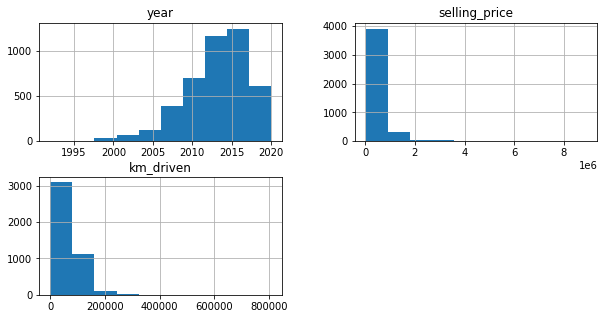

In [ ]:
df.hist(figsize = (10,5))

## Busqueda de nulos y sustitución

In [ ]:
#chequeo nulos
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [ ]:
#añadimos fake nulos
df.selling_price.iloc[1] = np.nan

/usr/local/lib/python3.7/dist-packages/pandas/core/indexing.py:1732: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)


In [ ]:
#comprobamos de nuevo nulos
df.isnull().sum()

name             0
year             0
selling_price    1
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [ ]:
df.head(5)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.00,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,NaN,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.00,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000.00,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000.00,141000,Diesel,Individual,Manual,Second Owner


#### Principales soluciones ante nulos

In [ ]:
#df.fillna(0).head()

In [ ]:
df = df[df['selling_price'].notna()]
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000.00,70000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000.00,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000.00,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000.00,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000.00,125000,Petrol,Individual,Manual,First Owner


In [ ]:
df.shape

(4339, 8)

## Matriz de correlación

In [ ]:
#matriz de correlacion
df.corr()

,year,selling_price,km_driven
year,1.00,0.41,-0.42
selling_price,0.41,1.00,-0.19
km_driven,-0.42,-0.19,1.00


# Funciones de agregación

In [ ]:
# groupby & agg
  ## reset_index + sort_values
  ## rename column

df.groupby(['year','name']).agg({'selling_price':'max'}).reset_index().sort_values(by = 'year' , ascending = False ).head(15)
# count
#mean
#max
#min
#nunique


# template = df.groupby('year').agg({'selling_price':['mean','max'] , 'km_driven':'mean'}).reset_index().sort_values(by = 'year' , ascending = False).rename(columns = {'selling_price':'average_selling_price'}).head()

,year,name,selling_price
2500,2020,Volkswagen Polo 1.0 TSI Highline Plus,802000
2469,2020,Ford Freestyle Titanium,811999
2477,2020,Hyundai Grand i10 Nios AMT Magna,640000
2476,2020,Hyundai Grand i10 1.2 Kappa Magna BSIV,545000
2475,2020,Hyundai Elite i20 Magna Plus BSIV,545000
2474,2020,Hyundai Creta 1.4 EX Diesel,1050000
2473,2020,Honda BR-V i-VTEC VX MT,1250000
2472,2020,Honda Amaze S Petrol BSIV,614000
2471,2020,Ford Freestyle Titanium Plus,852000
2470,2020,Ford Freestyle Titanium Diesel,784000


In [ ]:
df_agg = df.groupby('year').agg({'selling_price':['mean','max'] , 'km_driven':'mean'}).reset_index().sort_values(by = 'year' , ascending = False).rename(columns = {'selling_price':'average_selling_price'})

# Visualización con pandas

In [ ]:
# scatter plot , line y bar plot

In [ ]:
df_agg.columns.values.tolist()

[('year', ''),
 ('average_selling_price', 'mean'),
 ('average_selling_price', 'max'),
 ('km_driven', 'mean')]

In [ ]:
df_agg.head()

year average_selling_price          km_driven
                          mean      max      mean
26  2020             818479.12  4700000  11037.17
25  2019            1059020.48  4950000  20912.48
24  2018             910770.46  4800000  27233.78
23  2017             768909.84  8150000  40485.76
22  2016             608364.09  8900000  55205.90

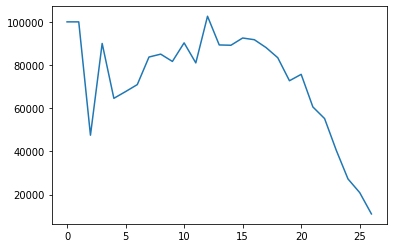

In [ ]:
#una columna plot
df_agg[('km_driven', 'mean')].plot()

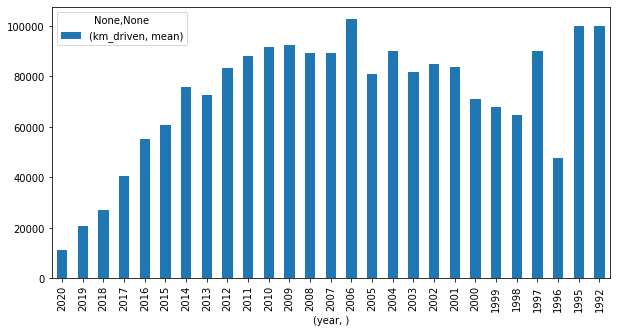

In [ ]:
# dado input de eje x e y

df_agg.plot( x = ('year', '') , y = ('km_driven', 'mean'), kind = 'bar' , figsize = (10,5))


In [ ]:
# filtro por columna
df_agg_hasta_2008 = df_agg[df_agg['year']>=2008]

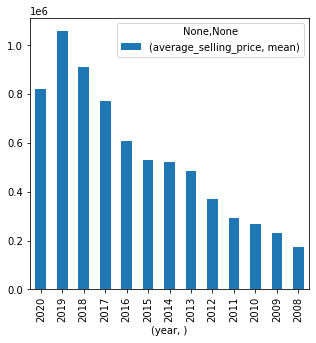

In [ ]:
# dado input de eje x e y con filtro

df_agg_hasta_2008.plot(x = ('year', '') , y = ('average_selling_price', 'mean'), kind = 'bar' , figsize = (5,5))

#Reto

In [ ]:
# 1) Entiende mediante una agregacion cual es el coche más caro por año y pinta los valores en un gráfico
# Consejo = renombra las columnas para que te sea más sencillo operar con ellas

# 2) Recomendación : ¿hay alguna ganga?
# Consejo = investiga si hay un coche relativamente nuevo (con pocos años) , con pocos km y a un precio menor con caracteristicas similares

## Reto1

In [ ]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [ ]:
df.shape

(4340, 8)

In [ ]:
df_agg = df.groupby(["year","name"]).agg( max_selling_price = ("selling_price" , "max")).reset_index().sort_values(by="max_selling_price" , ascending = False)
df_agg.head()

,year,name,max_selling_price
1659,2016,Audi RS7 2015-2019 Sportback Performance,8900000
2048,2017,Mercedes-Benz S-Class S 350d Connoisseurs Edition,8150000
1813,2016,Mercedes-Benz GLS 2016-2020 350d 4MATIC,5500000
2330,2019,BMW X5 xDrive 30d xLine,4950000
2328,2019,BMW 5 Series 520d Luxury Line,4800000


/usr/local/lib/python3.9/dist-packages/pandas/plotting/_matplotlib/core.py:1114: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


<Axes: xlabel='year', ylabel='max_selling_price'>

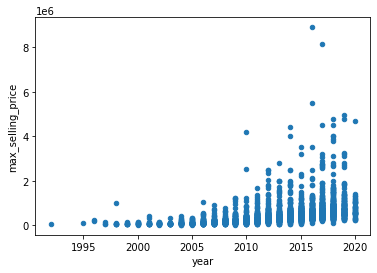

In [ ]:
df_agg.plot(x = "year" , y = "max_selling_price" , kind = "scatter")

## Reto2

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [ ]:
import datetime

current_year = datetime.datetime.now().year #get current year
df['Current Year'] = datetime.datetime.now().year
df["Years_Since"] = df['Current Year'] - df['year']  # substract to get the year delta


In [ ]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,Current Year,Years_Since
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,2023,16
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,2023,16
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,2023,11
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,2023,6
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,2023,9


<Axes: xlabel='Years_Since', ylabel='selling_price'>

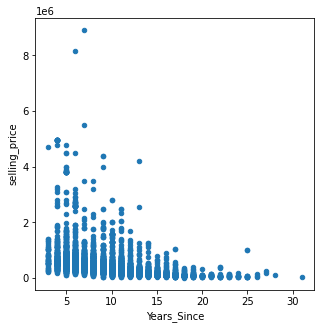

In [ ]:
df.plot( x = "Years_Since" , y = "selling_price" , kind = "scatter" , figsize = (5,5))

<Axes: xlabel='km_driven', ylabel='selling_price'>

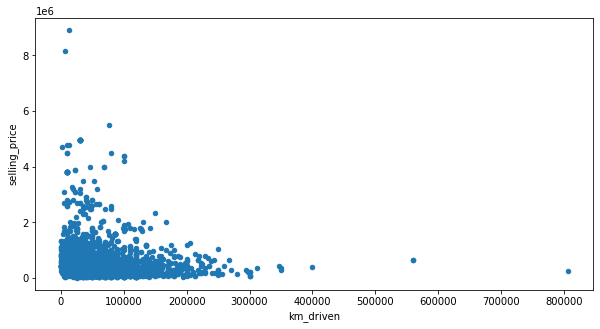

In [ ]:
df.plot( x = "km_driven" , y = "selling_price" , kind = "scatter" , figsize = (10,5))

In [ ]:
df.sort_values(by = ["Years_Since" , "selling_price" ] , ascending = True).head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,Current Year,Years_Since
3422,Maruti Alto 800 VXI,2020,210000,40000,Petrol,Individual,Manual,First Owner,2023,3
158,Maruti Wagon R LXI,2020,240000,120000,Petrol,Individual,Manual,First Owner,2023,3
1595,Maruti Alto K10 LX,2020,250000,1100,Petrol,Individual,Manual,Fourth & Above Owner,2023,3
176,Maruti Alto K10 LXI CNG,2020,282000,40000,CNG,Individual,Manual,First Owner,2023,3
1575,Renault KWID RXL,2020,300000,20000,Petrol,Individual,Manual,First Owner,2023,3


In [ ]:
# asumimos que no solo queremos coches de maximo 3 años y 45000 km

In [ ]:
df_agg_chollo = df[ (df["km_driven"] <=  45000) & (df["Years_Since"] <= 3)]

In [ ]:
df_agg_chollo.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,Current Year,Years_Since
176,Maruti Alto K10 LXI CNG,2020,282000,40000,CNG,Individual,Manual,First Owner,2023,3
289,Mahindra XUV500 W11 Option AWD,2020,1400000,25000,Diesel,Dealer,Manual,First Owner,2023,3
694,Hyundai Grand i10 Nios Magna CRDi,2020,700000,1400,Diesel,Individual,Manual,First Owner,2023,3
963,Audi A5 Sportback,2020,4700000,1500,Diesel,Individual,Automatic,First Owner,2023,3
1002,Hyundai Creta 1.4 EX Diesel,2020,1050000,10000,Diesel,Individual,Manual,First Owner,2023,3
